In [2]:
#Load and inspect the ENSDF-derived dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df1 = pd.read_csv("ensdf_ground_state_candidates.csv")
df2 = pd.read_csv("eda_df.csv")

print("Dataset shape:", df1.shape)
display(df1.head())

Dataset shape: (3371, 20)


,nuclide,element,Z,A,N,dataset_name,ground_energy_keV,spin_parity_raw,half_life_raw,half_life_value,half_life_unit,half_life_seconds,half_life_status,Q_beta_keV,S_n_keV,S_p_keV,Q_alpha_keV,ground_state_ambiguous,ground_state_candidate_count,source_file
0,1H,H,1,1,0,ADOPTED LEVELS,0.0,1/2+,STABLE,NaN,NaN,NaN,stable,NaN,NaN,NaN,NaN,False,1,ensdf.001
1,2H,H,1,2,1,ADOPTED LEVELS,0.0,1+,STABLE,NaN,NaN,NaN,stable,NaN,2224.566,2224.566,1.0,False,1,ensdf.002
2,3H,H,1,3,2,ADOPTED LEVELS,0.0,1/2+,12.32 Y,12.32,Y,388789632.0,finite,18.5906,6257.233,NaN,NaN,False,1,ensdf.003
3,3HE,HE,2,3,1,ADOPTED LEVELS,0.0,1/2+,STABLE,NaN,NaN,NaN,stable,NaN,NaN,5493.477,NaN,False,1,ensdf.003
4,4H,H,1,4,3,ADOPTED LEVELS,0.0,2-,NaN,NaN,NaN,NaN,missing,NaN,NaN,NaN,NaN,False,1,ensdf.004


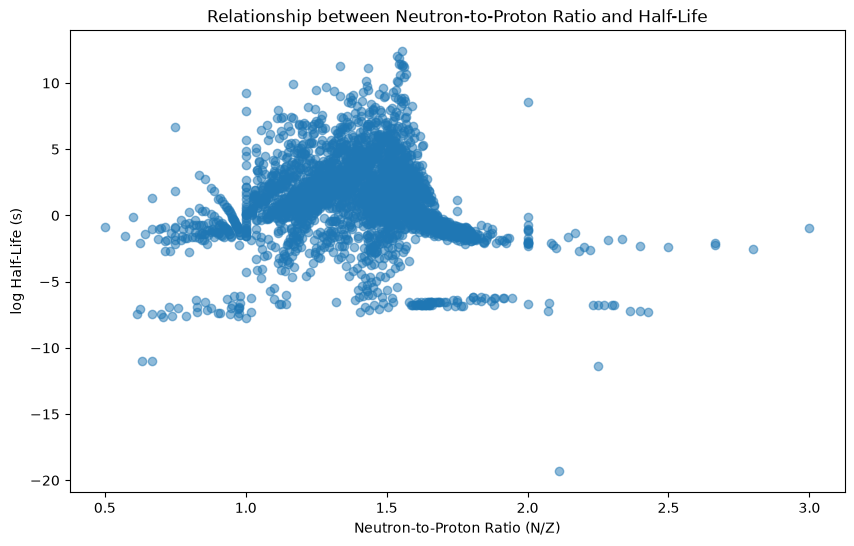

In [21]:
# Plot neutron-to-proton ratio (N/Z) vs. half-life to visualize the relationship between mass number and half-life
plt.figure(figsize=(10, 6))
plt.scatter(df[df["Z"] > 0]["N"] / df[df["Z"] > 0]["Z"], (df[df["Z"] > 0]["log_half_life"]), alpha=0.5)
plt.xlabel("Neutron-to-Proton Ratio (N/Z)")
plt.ylabel("log Half-Life (s)")
plt.title("Relationship between Neutron-to-Proton Ratio and Half-Life")
plt.show()

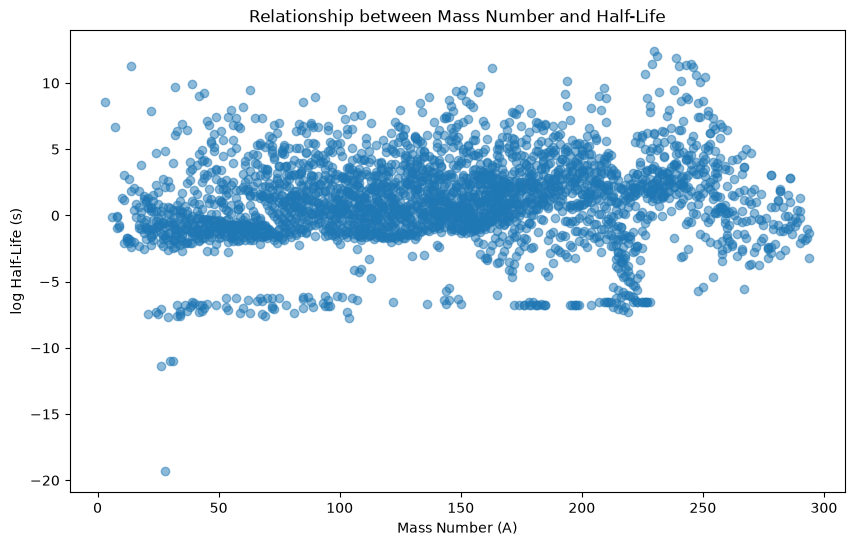

In [20]:
# Plot mass number (A) vs. half-life (s) to visualize the relationship between mass number and half-life
plt.figure(figsize=(10, 6))
plt.scatter(df[df["Z"] > 0]["A"], (df[df["Z"] > 0]["log_half_life"]), alpha=0.5)
plt.xlabel("Mass Number (A)")
plt.ylabel("log Half-Life (s)")
plt.title("Relationship between Mass Number and Half-Life")
plt.show()

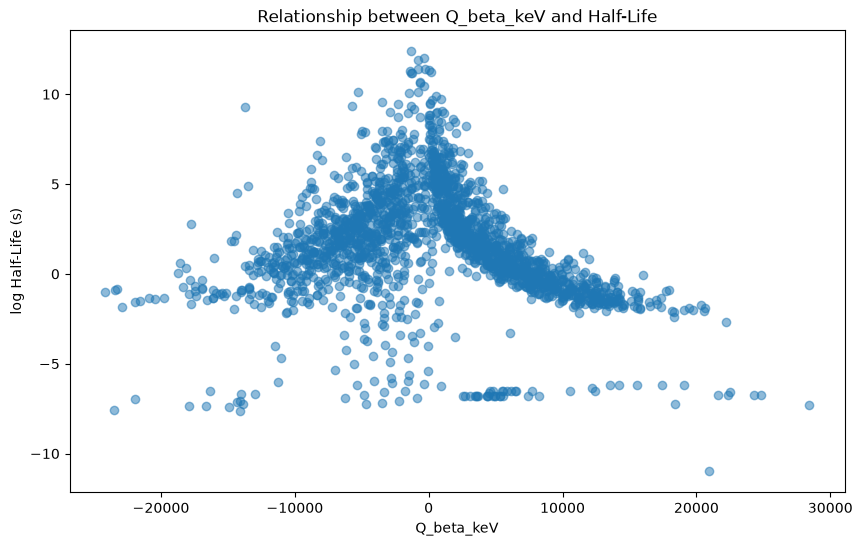

In [19]:
# Plot Q_beta_kev vs. half-life (s) to visualize the relationship between Q_beta and half-life
plt.figure(figsize=(10, 6))
plt.scatter(df[df["Q_beta_keV"].notnull()]["Q_beta_keV"], (df[df["Q_beta_keV"].notnull()]["log_half_life"]), alpha=0.5)
plt.xlabel("Q_beta_keV")
plt.ylabel("log Half-Life (s)")
plt.title("Relationship between Q_beta_keV and Half-Life")
plt.show()

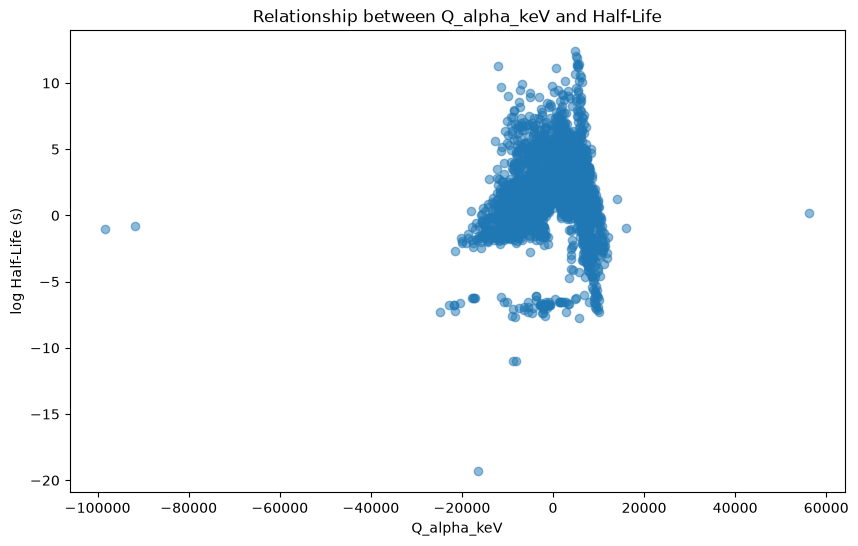

In [24]:
# Plot Q_alpha_kev vs. half-life (s) to visualize the relationship between Q_alpha and half-life
plt.figure(figsize=(10, 6))
plt.scatter(df[(df["Q_alpha_keV"].notnull()) & (df["Q_alpha_keV"]) & (df["Q_alpha_keV"])]["Q_alpha_keV"], (df[(df["Q_alpha_keV"].notnull()) & (df["Q_alpha_keV"]) & (df["Q_alpha_keV"])]["log_half_life"]), alpha=0.5)
plt.xlabel("Q_alpha_keV")
plt.ylabel("log Half-Life (s)")
plt.title("Relationship between Q_alpha_keV and Half-Life")
plt.show()

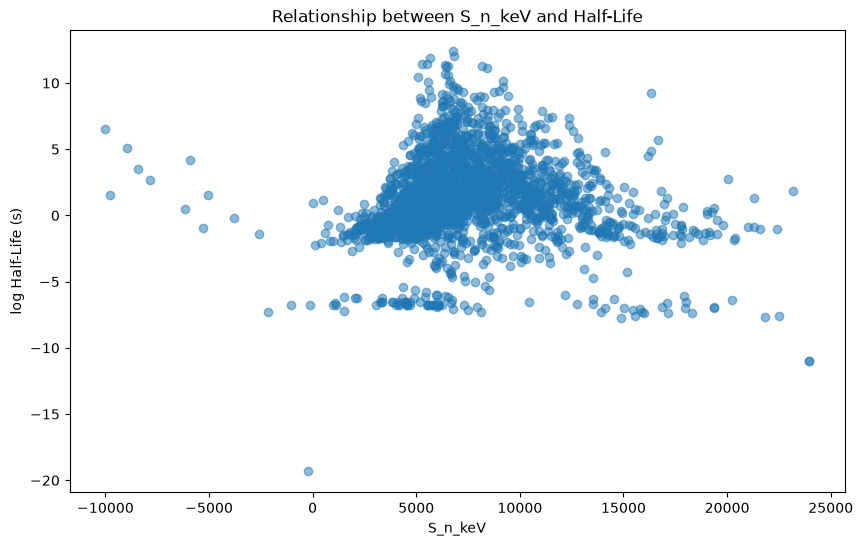

In [25]:
# Plot S_n_keV vs. half-life (s) to visualize the relationship between S_n_keV and half-life
plt.figure(figsize=(10, 6))
plt.scatter(df[df["S_n_keV"].notnull()]["S_n_keV"], (df[df["S_n_keV"].notnull()]["log_half_life"]), alpha=0.5)
plt.xlabel("S_n_keV")
plt.ylabel("log Half-Life (s)")
plt.title("Relationship between S_n_keV and Half-Life")
plt.show()

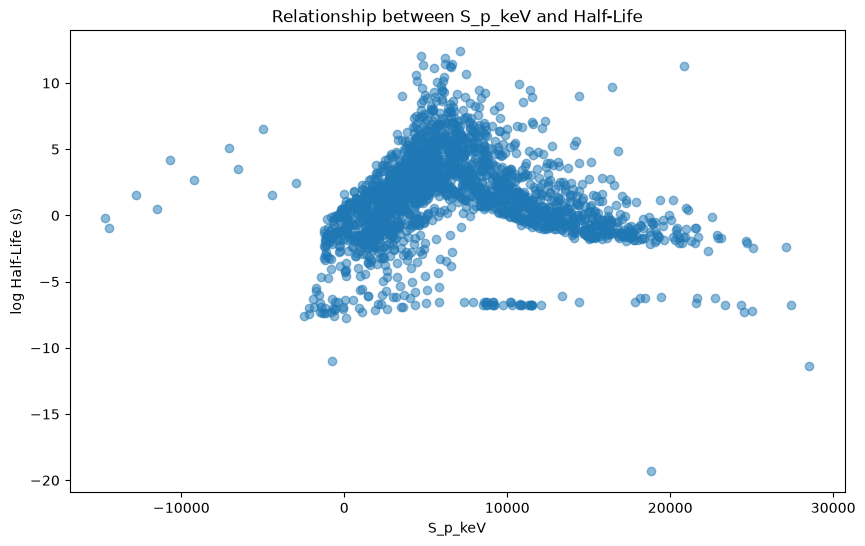

In [28]:
# Plot S_p_keV vs. half-life (s) to visualize the relationship between S_p_keV and half-life
plt.figure(figsize=(10, 6))
plt.scatter(df[df["S_p_keV"].notnull()]["S_p_keV"], (df[df["S_p_keV"].notnull()]["log_half_life"]), alpha=0.5)
plt.xlabel("S_p_keV")
plt.ylabel("log Half-Life (s)")
plt.title("Relationship between S_p_keV and Half-Life")
plt.show()

Feature coverage
---------------------------------------------
A                           2796/2796   (100.0%)
Z                           2796/2796   (100.0%)
log_half_life               2796/2796   (100.0%)
Q_alpha_keV                 2181/2796   (78.0%)
Q_beta_keV                  1970/2796   (70.5%)
S_n_keV                     2172/2796   (77.7%)
S_p_keV                     2166/2796   (77.5%)


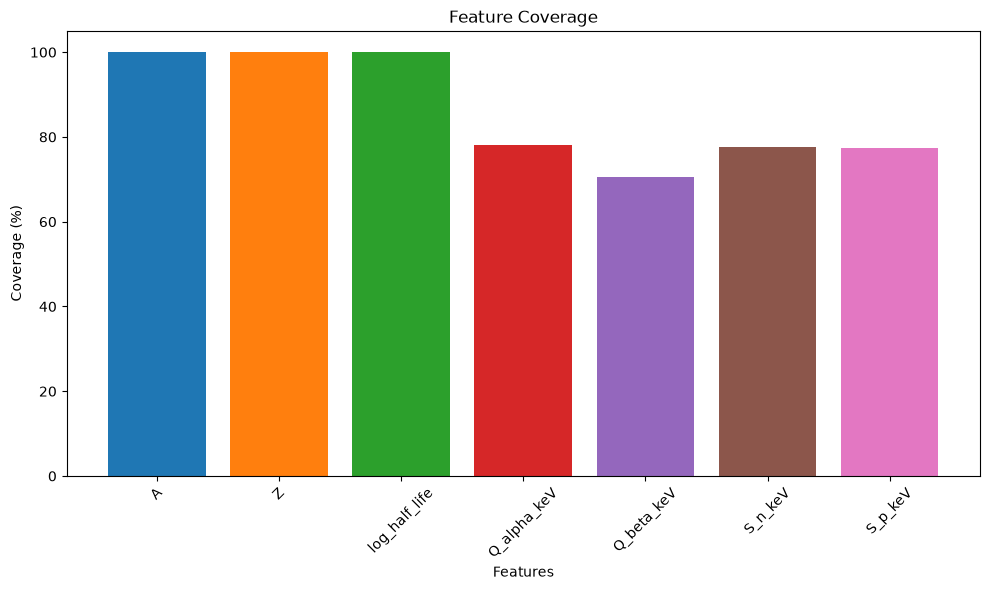

In [36]:
# Check feature coverage.

features = [
    "A",
    "Z",
    "log_half_life",
    "Q_alpha_keV",
    "Q_beta_keV",
    "S_n_keV",
    "S_p_keV",
]

print("Feature coverage")
print("-" * 45)

for feature in features:
    available = sum(
        df[feature].notnull() & (df[feature] != "")
    )

    total = len(df)
    percentage = 100 * available / total if total else 0

    print(
        f"{feature:25s} "
        f"{available:6d}/{total:<6d} "
        f"({percentage:.1f}%)"
    )

# Create a bar chart to visualize the coverage of each feature.
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
for feature in features:
    available = sum(
        df[feature].notnull() & (df[feature] != "")
    )

    total = len(df)
    percentage = 100 * available / total if total else 0
    
    plt.bar(feature, percentage)
plt.xlabel("Features")
plt.ylabel("Coverage (%)")
plt.title("Feature Coverage")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


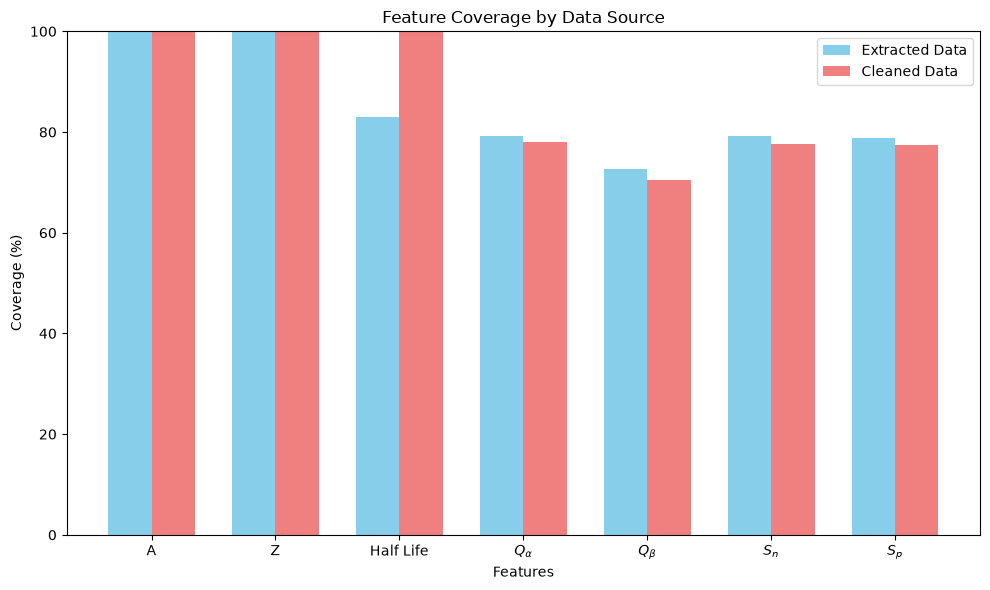

In [50]:

import matplotlib.pyplot as plt
import numpy as np

# 1. Define the features to compare
features = [
    "A",
    "Z",
    "half_life_seconds",
    "Q_alpha_keV",
    "Q_beta_keV",
    "S_n_keV",
    "S_p_keV",
]

display_labels = [
    "A",
    "Z",
    "Half Life",
    r"$Q_{\alpha}$",
    r"$Q_{\beta}$",
    r"$S_n$",
    r"$S_p$",
]

# 2. Define the function to calculate coverage
def calculate_coverage(df, features, column_mapping=None):
    percentages = []

    for feature in features:
        column = (column_mapping or {}).get(feature, feature)

        available = (
            df[column].notnull() & (df[column] != "")
        ).sum()

        total = len(df)
        percentage = 100 * available / total if total else 0

        percentages.append(percentage)

    return percentages


# 3. Calculate coverage for both data sources
coverage1 = calculate_coverage(df1, features)

coverage2 = calculate_coverage(
    df2,
    features,
    column_mapping={
        "half_life_seconds": "log_half_life"
    }
)

# 4. Plot the grouped bar chart
x = np.arange(len(features))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, coverage1, width, label="Extracted Data", color='skyblue')
plt.bar(x + width/2, coverage2, width, label="Cleaned Data", color='lightcoral')

plt.xlabel("Features")
plt.ylabel("Coverage (%)")
plt.title("Feature Coverage by Data Source")
plt.xticks(x, display_labels, rotation=0, ha="center")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()


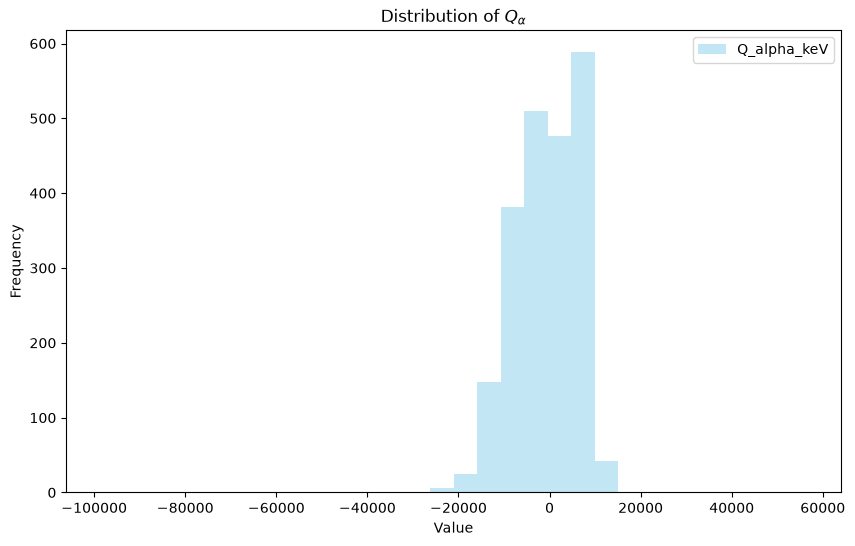

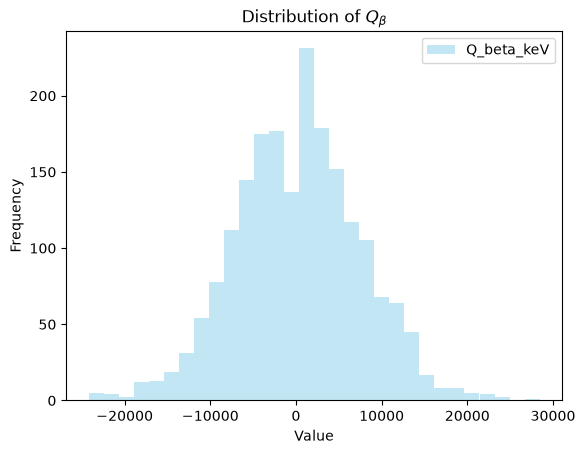

In [63]:
# Plot side by side histograms for Q values to visualize their distributions.

features = [
    "Q_alpha_keV",
    "Q_beta_keV"
]

Labels = [
    r"$Q_{\alpha}$",
    r"$Q_{\beta}$"
]

plt.figure(figsize=(10, 6))
for feature in features:
    plt.hist(df[feature].dropna(), bins=30, alpha=0.5, label=feature, color='skyblue')
    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {Labels[features.index(feature)]}")
    plt.legend()    
    plt.show()


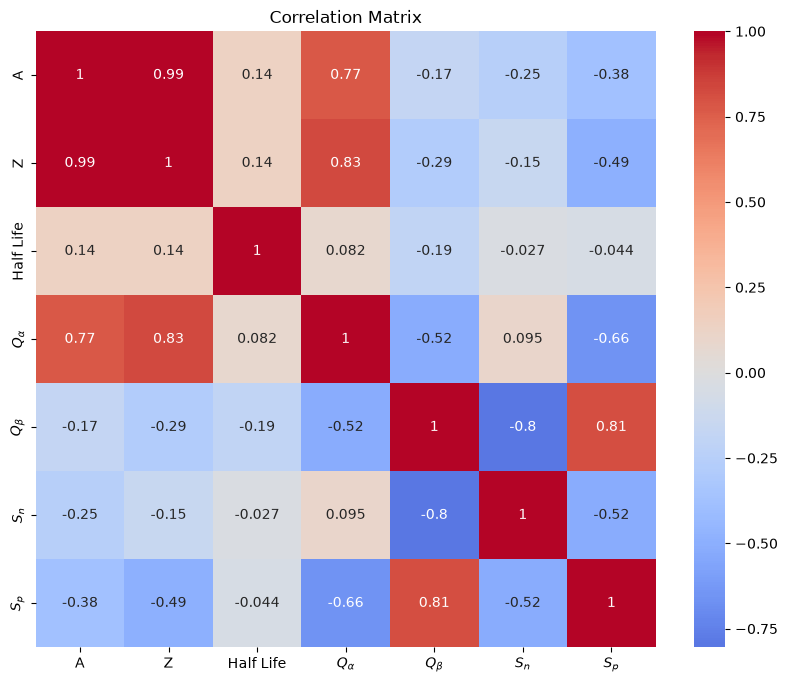

In [4]:
# Make a heatmap of the correlation matrix to visualize the relationships between only Z, N, A, Q_beta_kev, Q_alpha_keV, S_n_keV, and S_p_keV in the dataset
import seaborn as sns
import matplotlib.pyplot as plt

features = [
    "A",
    "Z",
    "log_half_life",
    "Q_alpha_keV",
    "Q_beta_keV",
    "S_n_keV",
    "S_p_keV",
]

display_labels = [
    "A",
    "Z",
    "Half Life",
    r"$Q_{\alpha}$",
    r"$Q_{\beta}$",
    r"$S_n$",
    r"$S_p$",
]

plt.figure(figsize=(10, 8))
sns.heatmap(df2[features].corr(), annot=True, cmap="coolwarm", center=0, xticklabels=display_labels, yticklabels=display_labels)
plt.title("Correlation Matrix")
plt.show()

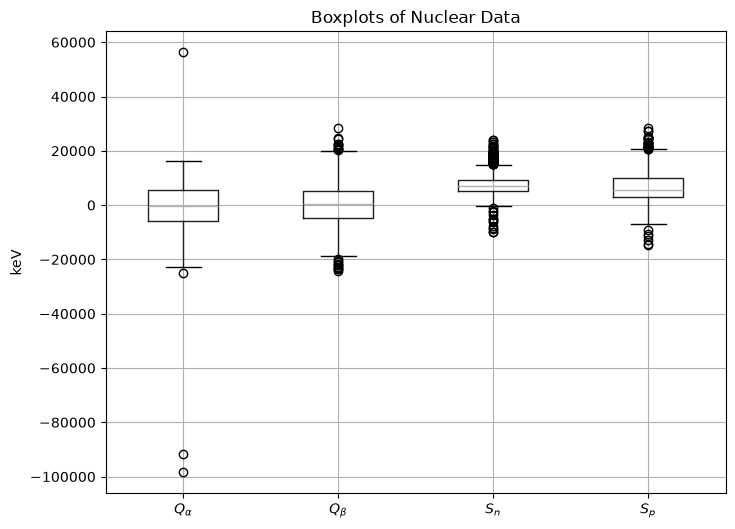

In [33]:
import matplotlib.pyplot as plt

features = [
    "Q_alpha_keV",
    "Q_beta_keV",
    "S_n_keV",
    "S_p_keV",
]

display_labels_boxplot = [
    r"$Q_{\alpha}$",
    r"$Q_{\beta}$",
    r"$S_n$",
    r"$S_p$",
]

fig, ax = plt.subplots(figsize=(8, 6))

df2.boxplot(column=features, ax=ax)

# Override the displayed x-axis labels
ax.set_xticklabels(display_labels_boxplot)

ax.set_title("Boxplots of Nuclear Data")
ax.set_ylabel("keV")

plt.show()